# 01 P1: vector-located crops read by Qwen3-VL 8B

**Question.** If we find each callout from the PDF's vector paths and show the model one crop at a time, how well does Qwen3-VL 8B read the values?

**Answer.** It finds most values, but it also reads too much. On the four drawings with full gold (CTC-01, CTC-03, FTC-06 and FTC-07 page 2) it finds 86% of the gold values exactly (recall 0.862), with precision 0.625 and F1 0.725. On the seven drawings with partial gold it finds 74% of the listed values (partial recall 0.743). It reads CTC-01 almost perfectly (F1 0.957). Most of the extra predictions are frame cells read again as bare numbers, notes split over two lines, and text from a neighbouring callout cut by the crop edge. It read the 30 pages in 32 minutes, 64 seconds per page, on an M1 Pro with 16 GB.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # notebooks run from experiments/drawing/
from notebook_helpers import (  # noqa: E402
    FULL_GOLD,
    ask_crop,
    case_table,
    evals,
    failures,
    locator_overlay,
    missed,
    stored_run,
)

## How the reader works

The reader is `VectorCropReaderAdapter` in `src/resourcly/adapters/vlm_readers.py`, and the version is `versions/reader/vector-crop-v1.toml`.

1. **Find the callouts with no model** (`callout_locator.py`). The annotation colour is the colour that holds the most letter-shaped paths, which is pure blue on these sheets. Every frame (a feature control frame or a datum box) is taken whole from its own path: a rectangle, a quad, or at least four straight lines in two directions. The letters inside a frame belong to it, so the symbol cell is never cut off. The other letters are grouped into text callouts, and a frame is never merged with a text group, so stacked callouts stay apart. These are the fixes for the two problems the research found in the prototype locator. On FTC-07, whose callouts are real text, the short text-layer lines count as letters.
2. **Crop each callout** at 300 dpi with a 4 pt margin. Other callouts that fall in the margin are painted white, so the model reads only this one.
3. **Ask Qwen3-VL 8B to transcribe the crop** with Prompt B from the research, unchanged: it lists the GD&T symbols and asks for lines and frame cells as JSON. If a frame comes back with no symbol name, one short follow-up asks for the symbol. If a datum box reads as nothing, one asks for its letter.
4. **Plain code does the rest** (`callout_values.py`): it joins stacked lines, spells `raw` the gold way, picks the callout type and kind, and computes value, limits and unit from the printed numbers. The title block and notes come from the PDF text layer.
5. **Feature typing is a fixed rule**, not traced: each callout is one feature, typed from what it says (a count such as 4X is a pattern, a diameter is a hole, and so on).

### The located callouts on the densest sheet (FTC-06 page 1)

Red boxes are frames and datum boxes, green boxes are text.

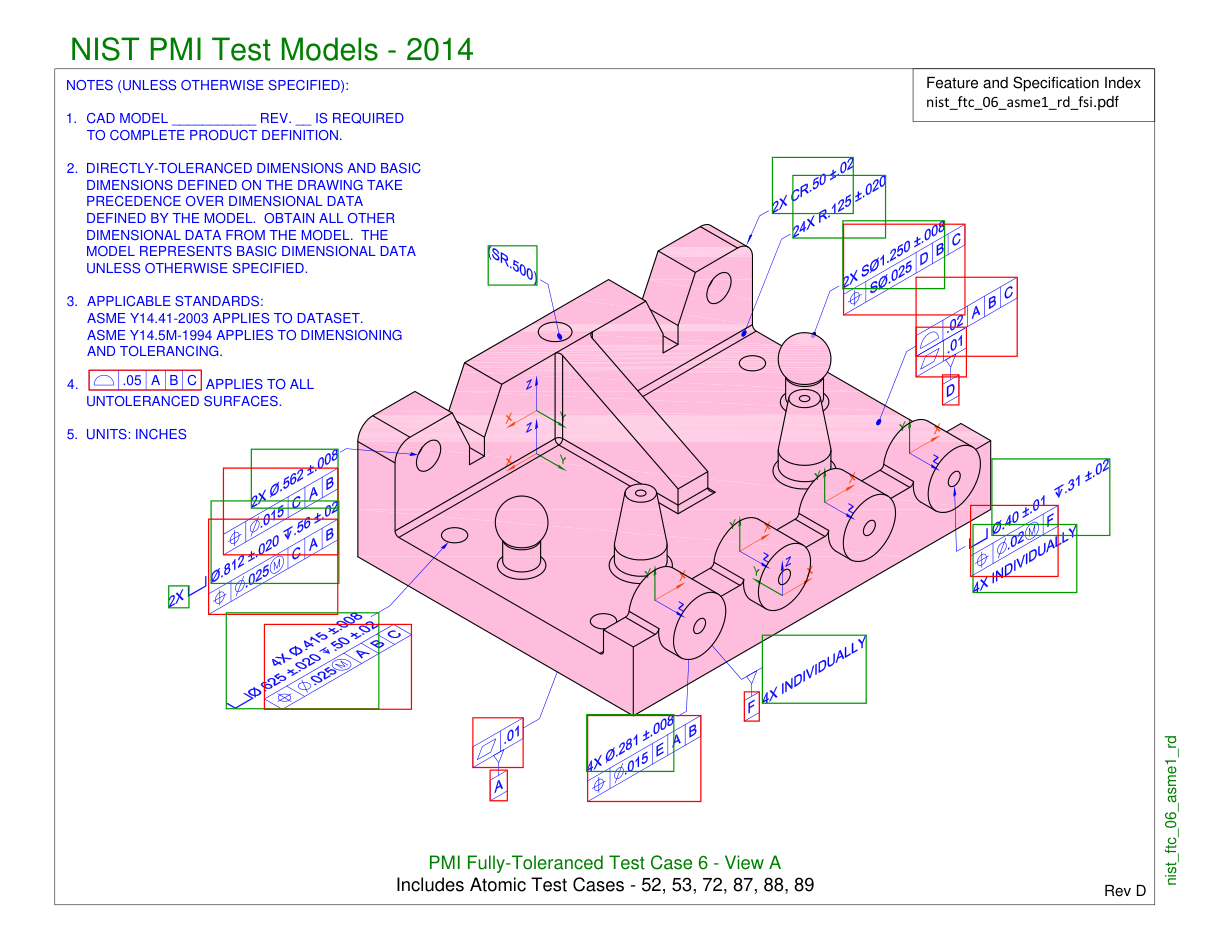

In [2]:
locator_overlay("nist_ftc_06_asme1_rd", 1)

## The run

The run reads all 11 drawings and is made from the command line, as it takes 32 minutes:

```sh
uv run --extra vlm evals run reader --version vector-crop-v1 --split all
```

This notebook reads it back from the run store. Four drawings have full gold (FTC-07 on page 2 only, through `page_coverage`) and give F1; the other seven have partial gold of about ten values and give recall only.

In [3]:
run_id = stored_run("vector-crop-v1")

In [4]:
evals("show", run_id)

run reader-20261102T043630Z-7f02  reader vector-crop-v1 (hash 48b6757c7e1d)
split all, every case, case set 8231118bad61
started 2026-11-02T04:36:30Z  finished 2026-11-02T05:08:24Z  git 6bcab14 with local changes

metric          value
f1 (primary)    0.725
precision       0.625
recall          0.862
partial_recall  0.743
errors          0 of 11

case                  stratum  case_score  gold  predicted  matched  latency    error
nist_ctc_01_asme1_rd  full     0.957       23    23         22       68824 ms
nist_ctc_02_asme1_rc  partial  0.700       10    83         7        188069 ms
nist_ctc_03_asme1_rc  full     0.630       37    55         29       120594 ms
nist_ctc_04_asme1_rd  partial  0.900       10    39         9        91386 ms
nist_ctc_05_asme1_rd  partial  0.500       10    34         5        63531 ms
nist_ftc_06_asme1_rd  full     0.759       89    114        77       218698 ms
nist_ftc_07_asme1_rd  full     0.603       25    48         22       216048 ms
nist_ftc_08_asm

'run reader-20261102T043630Z-7f02  reader vector-crop-v1 (hash 48b6757c7e1d)\nsplit all, every case, case set 8231118bad61\nstarted 2026-11-02T04:36:30Z  finished 2026-11-02T05:08:24Z  git 6bcab14 with local changes\n\nmetric          value\nf1 (primary)    0.725\nprecision       0.625\nrecall          0.862\npartial_recall  0.743\nerrors          0 of 11\n\ncase                  stratum  case_score  gold  predicted  matched  latency    error\nnist_ctc_01_asme1_rd  full     0.957       23    23         22       68824 ms\nnist_ctc_02_asme1_rc  partial  0.700       10    83         7        188069 ms\nnist_ctc_03_asme1_rc  full     0.630       37    55         29       120594 ms\nnist_ctc_04_asme1_rd  partial  0.900       10    39         9        91386 ms\nnist_ctc_05_asme1_rd  partial  0.500       10    34         5        63531 ms\nnist_ftc_06_asme1_rd  full     0.759       89    114        77       218698 ms\nnist_ftc_07_asme1_rd  full     0.603       25    48         22       216048

In [5]:
case_table(run_id)

,gold,gold values,predicted,matched,precision,recall,F1,pages,seconds,seconds per page,error
drawing,,,,,,,,,,,
nist_ctc_01_asme1_rd,full,23,23,22,0.957,0.957,0.957,1,68.8,68.8,None
nist_ctc_02_asme1_rc,partial,10,83,7,NaN,0.700,NaN,3,188.1,62.7,None
nist_ctc_03_asme1_rc,full,37,55,29,0.527,0.784,0.630,1,120.6,120.6,None
nist_ctc_04_asme1_rd,partial,10,39,9,NaN,0.900,NaN,1,91.4,91.4,None
nist_ctc_05_asme1_rd,partial,10,34,5,NaN,0.500,NaN,2,63.5,31.8,None
nist_ftc_06_asme1_rd,full,89,114,77,0.675,0.865,0.759,3,218.7,72.9,None
nist_ftc_07_asme1_rd,full,25,48,22,0.458,0.880,0.603,4,216.0,54.0,None
nist_ftc_08_asme1_rc,partial,10,123,8,NaN,0.800,NaN,4,260.4,65.1,None
nist_ftc_09_asme1_rd,partial,10,147,10,NaN,1.000,NaN,4,297.1,74.3,None


## Failure cases

Each missed gold record and each extra prediction, with the page region around it.

**nist_ctc_01_asme1_rd**: 1 missed, 1 extra predictions

missed: page 1 `perpendicularity` `⊥ 1.5 | A` value 1.5

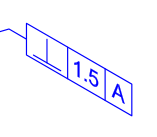

extra predictions: page 1 `flatness` `▱ 1.5` value 1.5

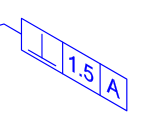

**nist_ctc_03_asme1_rc**: 8 missed, 26 extra predictions

missed: page 1 `note` `SWITCH MOUNTING LOCATIONS` value None

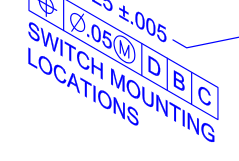

missed: page 1 `note` `2 COPLANAR SURFACES` value None

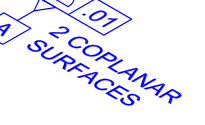

missed: page 1 `angularity` `∠ .04 | A` value 0.04

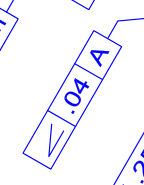

missed: page 1 `flatness` `▱ .005 / .25 X .25` value 0.005

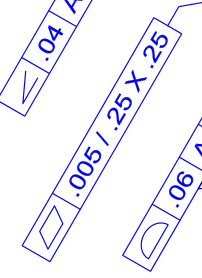

missed: page 1 `datum_feature` `E` value None

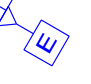

missed: page 1 `perpendicularity` `⊥ ⌀.01 | A` value 0.01

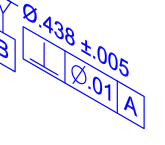

missed: page 1 `position` `⌖ ⌀.08 | D | B | C` value 0.08

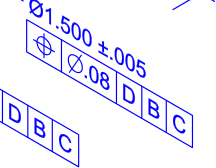

missed: page 1 `position` `⌖ .03 | D | B | C` value 0.03

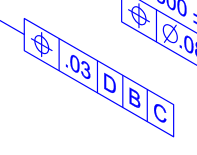

extra predictions: page 1 `linear` `0.06 | D` value 0.06

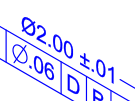

extra predictions: page 1 `note` `2 COPLANAR` value None

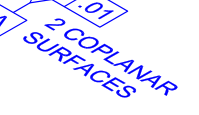

extra predictions: page 1 `note` `SURFACES` value None

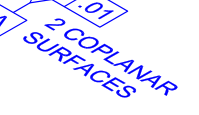

extra predictions: page 1 `position` `⌖ ⌀.05Ⓜ | D | B | C` value 0.05

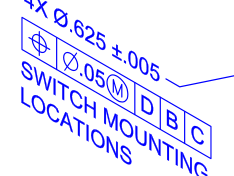

extra predictions: page 1 `diameter` `⌀.625 ±.005` value 0.625

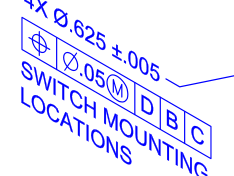

extra predictions: page 1 `note` `SWITCH MOUNTING` value None

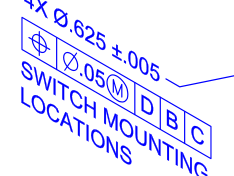

extra predictions: page 1 `note` `LOCATIONS` value None

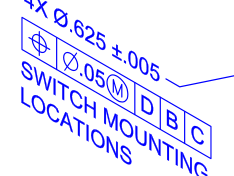

extra predictions: page 1 `position` `⌖ ⌀.438±.005` value 0.438

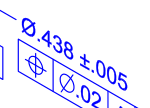

extra predictions: page 1 `linear` `+.38 ±.005` value 0.38

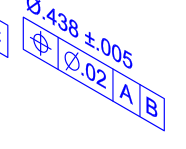

extra predictions: page 1 `circularity` `○ ⌀0.065` value 0.065

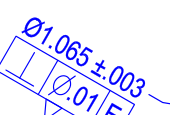

extra predictions: page 1 `circularity` `○ 0.01` value 0.01

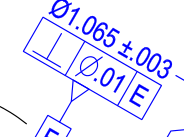

extra predictions: page 1 `linear` `1.065 ±.00` value 1.065

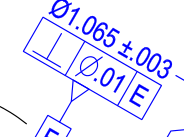

**nist_ftc_06_asme1_rd**: 12 missed, 37 extra predictions

missed: page 1 `radius` `24X R.125 ±.020` value 0.125

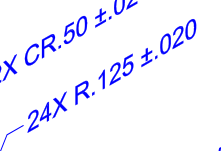

missed: page 1 `linear` `↧.50 ±.02` value 0.5

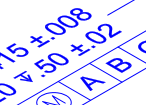

missed: page 1 `flatness` `▱ .01` value 0.01

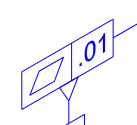

missed: page 1 `title_block` `Feature and Specification Index nist_ftc_06_asme1_rd_fsi.pdf` value None

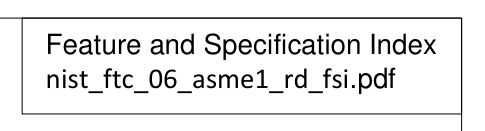

missed: page 2 `angular` `⌳ 1.00 : 2.00` value None

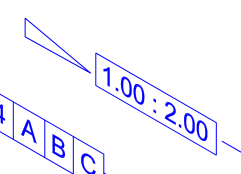

missed: page 2 `angular` `2X ⌲ 1.00 : 3.00` value None

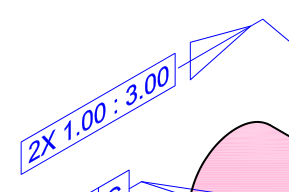

missed: page 2 `flatness` `▱ .01` value 0.01

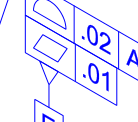

missed: page 2 `profile_of_a_surface` `⌓ .05 | D | B | C` value 0.05

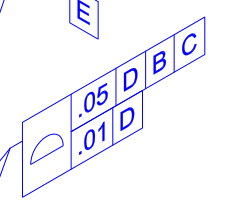

missed: page 2 `perpendicularity` `⊥ .012 | A | B` value 0.012

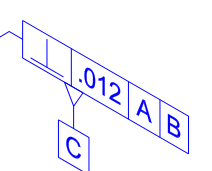

missed: page 2 `perpendicularity` `⊥ .012 | A` value 0.012

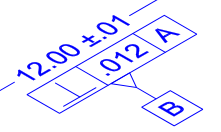

missed: page 3 `datum_target` `G1` value None

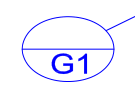

missed: page 3 `datum_target` `H1` value None

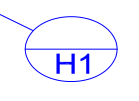

extra predictions: page 1 `linear` `≈ 125` value 125

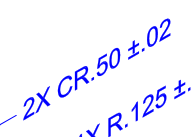

extra predictions: page 1 `linear` `-24X R.125 ±.020` value 0.125

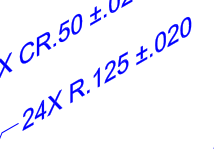

extra predictions: page 1 `diameter` `S⌀.025` value 0.025

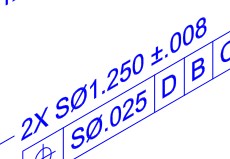

extra predictions: page 1 `diameter` `2X S⌀1.250 ±.00b` value 1.25

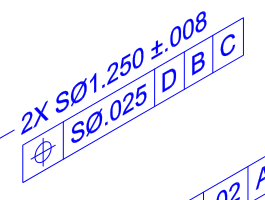

extra predictions: page 1 `radius` `(SR.500) -` value 0.5

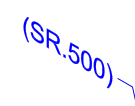

extra predictions: page 1 `profile_of_a_surface` `⌓ .01` value 0.01

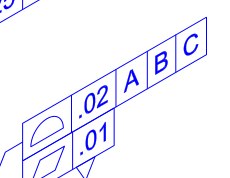

extra predictions: page 1 `position` `⌖ ⌀.562 | C | A | B` value 0.562

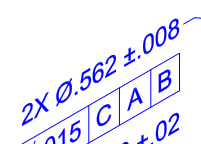

extra predictions: page 1 `circularity` `○ ⌀.40 | F` value 0.4

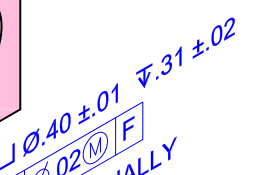

extra predictions: page 1 `diameter` `2X ⌀.562 ±.` value None

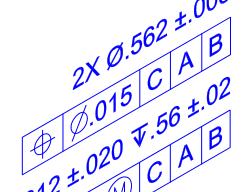

extra predictions: page 1 `diameter` `⌀.56 ±.02` value 0.56

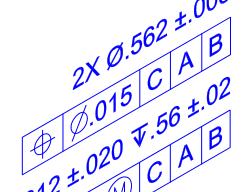

extra predictions: page 1 `diameter` `⌀.015` value 0.015

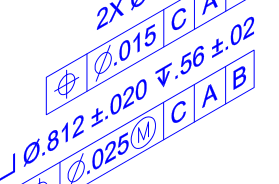

extra predictions: page 1 `position` `⌖ ⌀.02Ⓜ | F` value 0.02

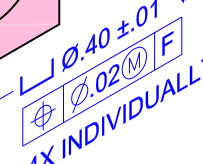

**nist_ftc_07_asme1_rd**: 3 missed, 26 extra predictions

missed: page 2 `note` `4 COPLANAR SURFACES` value None

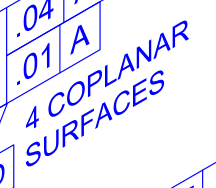

missed: page 2 `flatness` `▱ .01 / ⌀1.00` value 0.01

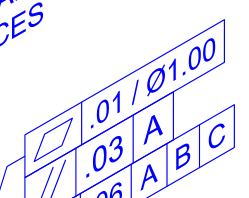

missed: page 2 `profile_of_a_surface` `⌓ .06 | A | B | C` value 0.06

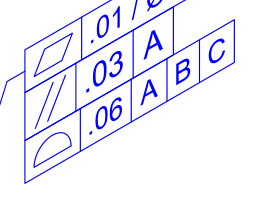

extra predictions: page 2 `note` `⌓ ±.010 | E | R` value None

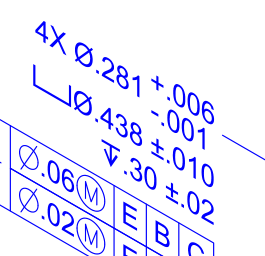

extra predictions: page 2 `note` `⌓ ±.02` value None

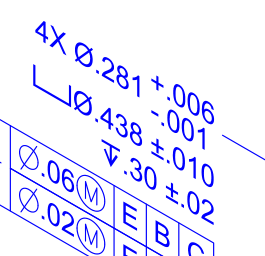

extra predictions: page 2 `diameter` `⌀.06(M) E R` value 0.06

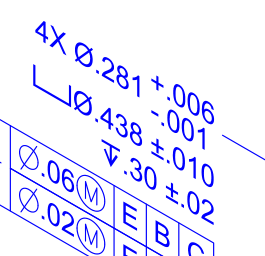

extra predictions: page 2 `diameter` `⌀.02(M)` value 0.02

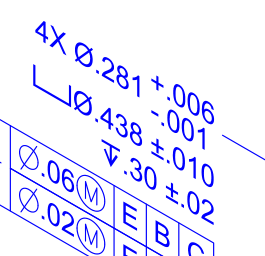

extra predictions: page 2 `note` `4 COPLANAR` value None

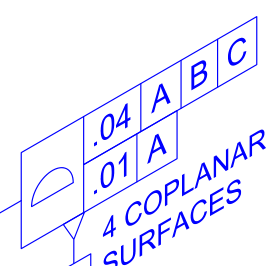

extra predictions: page 2 `note` `SURFACES` value None

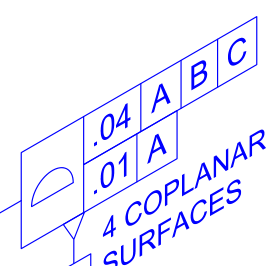

extra predictions: page 2 `diameter` `⌀.438 ±.001` value 0.438

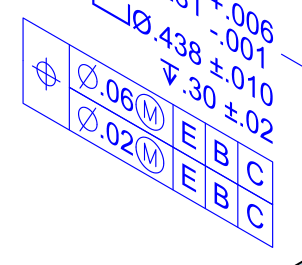

extra predictions: page 2 `diameter` `⌀.06 M` value 0.06

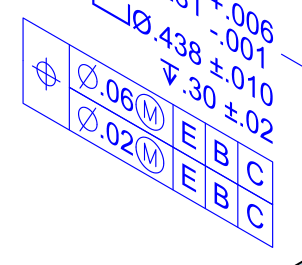

extra predictions: page 2 `diameter` `⌀.02 M` value 0.02

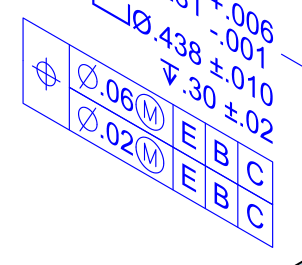

extra predictions: page 2 `linear` `.04` value 0.04

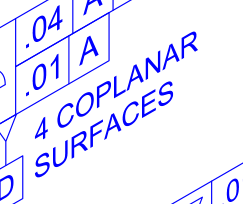

extra predictions: page 2 `linear` `.01 A` value 0.01

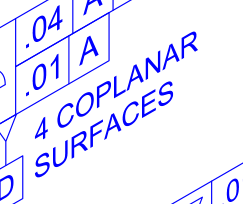

extra predictions: page 2 `diameter` `.01 / ⌀1.00` value 0.01

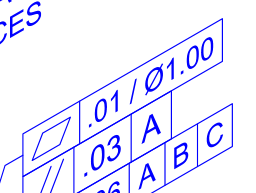

In [6]:
for case_id in FULL_GOLD:
    failures(run_id, case_id)

### What the model said about some missed callouts

The crop the reader sent for the first three missed frames on FTC-06, and the model's raw answer.

▱ .01


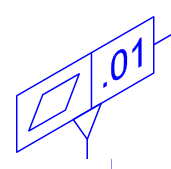

{"lines": [".01"], "feature_control_frames": [{"symbol_name": "flatness", "tolerance": "0.01", "modifiers": [], "datums": []}]}
▱ .01


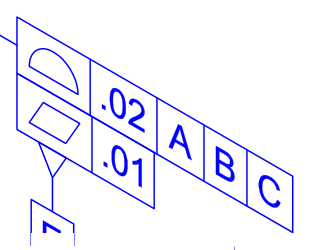

{"lines": [".02", ".01"], "feature_control_frames": [{"symbol_name": "profile of a surface", "tolerance": ".02", "modifiers": [], "datums": ["A", "B", "C"]}, {"symbol_name": "profile of a surface", "tolerance": ".01", "modifiers": [], "datums": []}]}


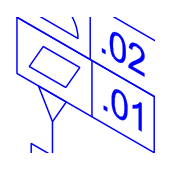

{"lines": [".02", ".01"], "feature_control_frames": []}


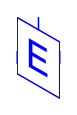

{"lines": [], "feature_control_frames": []}
⌓ .05 | D | B | C


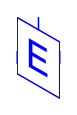

{"lines": [], "feature_control_frames": []}


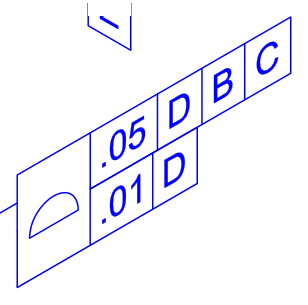

{"lines": [".05 D B C", ".01 D"], "feature_control_frames": []}


In [7]:
ftc06_frames = [r for r in missed(run_id, "nist_ftc_06_asme1_rd") if r["callout"] == "feature_control_frame"]
for record in ftc06_frames[:3]:
    print(record["raw"])
    ask_crop("vector-crop-v1", "nist_ftc_06_asme1_rd", record["page"], record["bbox"])